### 1. Imports & chargement des données

In [75]:

import shap
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
import matplotlib.pyplot as plt

from scipy.stats import randint, uniform
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, 
    f1_score, recall_score, make_scorer,
    precision_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

X_train = pd.read_csv("../data/weatherAUS_X_train.csv")
y_train = pd.read_csv("../data/weatherAUS_y_train.csv")

X_test = pd.read_csv("../data/weatherAUS_X_test.csv")
y_test = pd.read_csv("../data/weatherAUS_y_test.csv")

### 2. Scaling

In [76]:
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

### 3. Entraînement du modèle de base (LGBMClassifier)

In [77]:
model = lgb.LGBMClassifier(n_estimators=500, class_weight='balanced', random_state=42, n_jobs=-1, importance_type='gain')
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

y_score_train_neg = model.predict_proba(X_train)[:, 0]
y_score_test_neg  = model.predict_proba(X_test)[:, 0]

y_score_train_pos = model.predict_proba(X_train)[:, 1]
y_score_test_pos  = model.predict_proba(X_test)[:, 1]

/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


#### 3.1 Métriques (F1, Recall, Précision, AUC-ROC, PR-AUC)

In [78]:
# Métriques du LGBMClassifier
f1_train = f1_score(y_train, y_pred_train, pos_label=1)
f1_test  = f1_score(y_test,  y_pred_test, pos_label=1)

recall_train   = recall_score(y_train, y_pred_train)
recall_test    = recall_score(y_test,  y_pred_test)

prec_train     = precision_score(y_train, y_pred_train)
prec_test      = precision_score(y_test,  y_pred_test)

auc_roc_train  = roc_auc_score(y_train, y_score_train_pos)
auc_roc_test   = roc_auc_score(y_test,  y_score_test_pos)

pr_auc_train   = average_precision_score(y_train, y_score_train_pos)
pr_auc_test    = average_precision_score(y_test,  y_score_test_pos)

In [79]:
sep = "─" * 52
print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LGBMClassifier':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train:>10.4f} {f1_test:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train:>10.4f} {recall_test:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train:>10.4f} {prec_test:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)

────────────────────────────────────────────────────
       ÉVALUATION DU MODÈLE — LGBMClassifier        
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.7584     0.6415
────────────────────────────────────────────────────
Recall  (classe Yes)             0.9015     0.7678
Précision (classe Yes)           0.6545     0.5508
────────────────────────────────────────────────────
AUC-ROC                          0.9560     0.8777
PR-AUC                           0.8664     0.7232
────────────────────────────────────────────────────


#### 3.2 Matrice de confusion

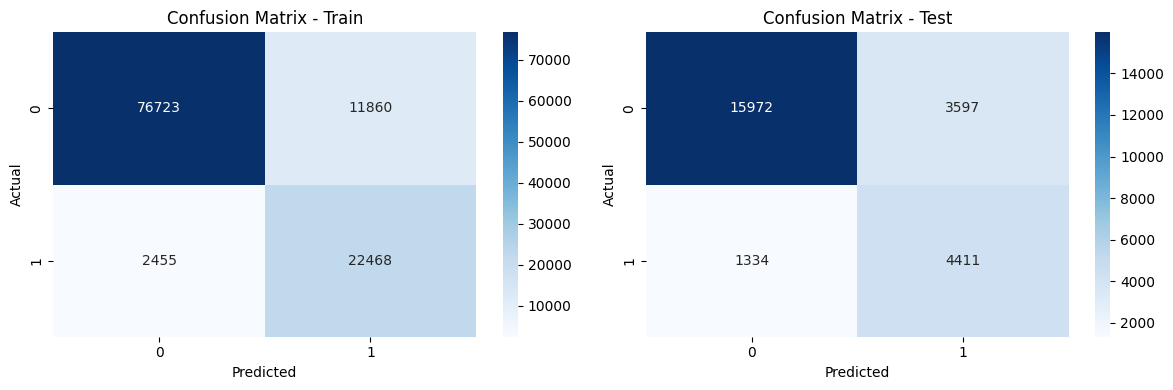

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, title in zip(axes, [y_pred_train, y_pred_test], ['Train', 'Test']):
    cm = confusion_matrix(y_train if title == 'Train' else y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

#### 3.3 Courbes AUC-ROC et PR-AUC

AUC-ROC - Train : 0.9560 | Test : 0.8777
PR-AUC  - Train : 0.8664 | Test : 0.7232


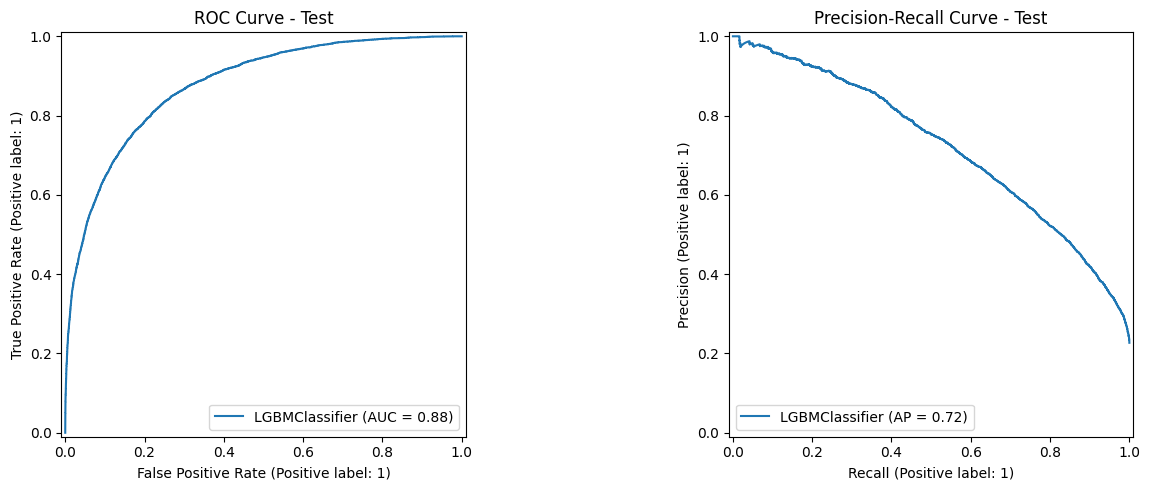

In [81]:
print(f"AUC-ROC - Train : {roc_auc_score(y_train, y_score_train_pos):.4f} | Test : {roc_auc_score(y_test, y_score_test_pos):.4f}")
print(f"PR-AUC  - Train : {average_precision_score(y_train, y_score_train_pos):.4f} | Test : {average_precision_score(y_test, y_score_test_pos):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_test, y_score_test_pos, ax=axes[0], name='LGBMClassifier')
axes[0].set_title('ROC Curve - Test')
PrecisionRecallDisplay.from_predictions(y_test, y_score_test_pos, ax=axes[1], name='LGBMClassifier')
axes[1].set_title('Precision-Recall Curve - Test')
plt.tight_layout()
plt.show()

#### 3.4 Courbe Précision / Recall vs Seuil

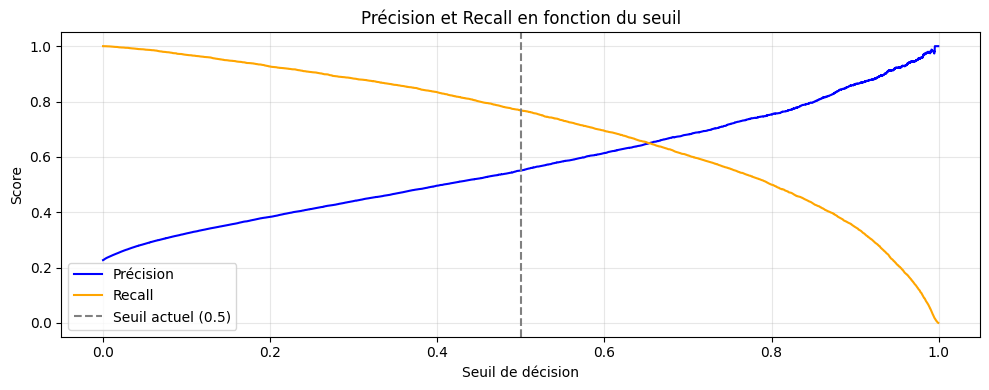

In [82]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_score_test_pos)

plt.figure(figsize=(10, 4))
plt.plot(thresholds, precisions[:-1], label='Précision', color='blue')
plt.plot(thresholds, recalls[:-1],    label='Recall',    color='orange')
plt.axvline(x=0.5, color='gray', linestyle='--', label='Seuil actuel (0.5)')
plt.xlabel('Seuil de décision')
plt.ylabel('Score')
plt.title('Précision et Recall en fonction du seuil')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.5 Importance des features

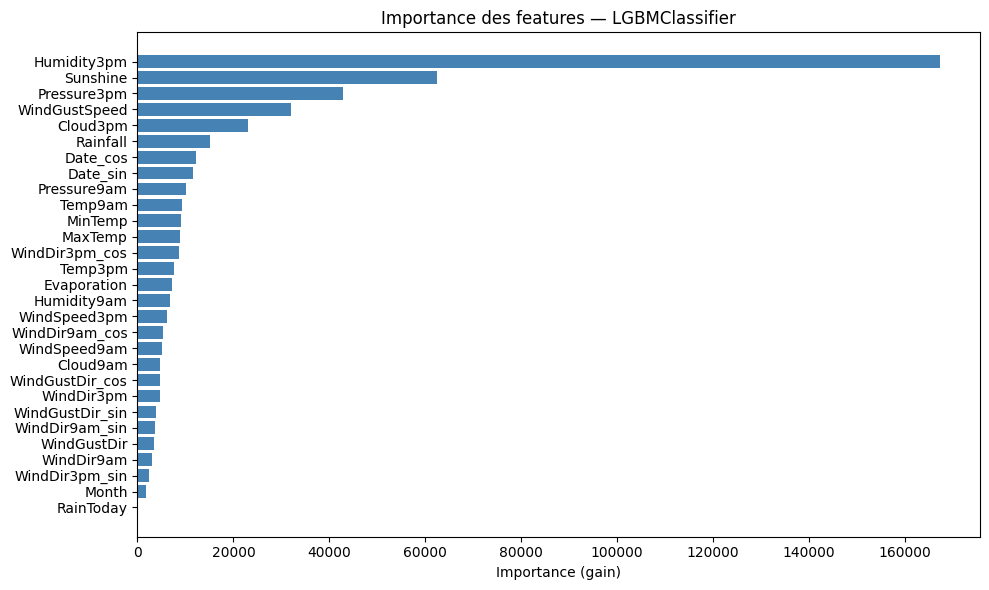

In [83]:
feature_names = X_train.columns
importances   = model.feature_importances_

imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
imp_df = imp_df.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(imp_df['feature'], imp_df['importance'], color='steelblue')
plt.xlabel('Importance (gain)')
plt.title('Importance des features — LGBMClassifier')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### 3.6 Courbe d'apprentissage (Learning Curve)

In [84]:
# from sklearn.model_selection import learning_curve

# model_lc = lgb.LGBMClassifier(
#     n_estimators=100, # au lieu de 500
#     class_weight='balanced',
#     random_state=42,
#     n_jobs=-1
# )

# train_sizes, train_scores, val_scores = learning_curve(
#     model_lc, X_train, y_train,
#     train_sizes=np.linspace(0.1, 1.0, 8),
#     scoring='f1', cv=3, n_jobs=-1
# )

# plt.figure(figsize=(10, 5))
# plt.plot(train_sizes, train_scores.mean(axis=1), label='Train',      color='blue')
# plt.plot(train_sizes, val_scores.mean(axis=1),   label='Validation', color='orange')
# plt.fill_between(train_sizes,
#                  train_scores.mean(axis=1) - train_scores.std(axis=1),
#                  train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='blue')
# plt.fill_between(train_sizes,
#                  val_scores.mean(axis=1) - val_scores.std(axis=1),
#                  val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='orange')
# plt.xlabel('Taille du train')
# plt.ylabel('F1-score (Yes)')
# plt.title('Learning Curve — LGBMClassifier')
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

### 4. Optimisation des hyperparamètres

#### 4.1 Pipeline + Grid Search

In [85]:
import time

param_distributions = {
    'num_leaves': randint(15, 100),
    'max_depth': randint(3, 15),
    'learning_rate': uniform(0.01, 0.19),
    'min_child_samples': randint(5, 80),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    
    # 'num_leaves': [15, 50, 75, 100],
    # 'max_depth': [3, 5, 10, 15],
    # 'learning_rate': [0.01, 0.1, 0.2],
}

randomized_search = RandomizedSearchCV(
    lgb.LGBMClassifier(n_estimators=500, class_weight='balanced', random_state=42, n_jobs=1, verbosity=-1),
    param_distributions=param_distributions,
    n_iter=20,
    scoring=make_scorer(f1_score, pos_label=1),
    cv=TimeSeriesSplit(n_splits=3, max_train_size=len(X_train) // 3),
    n_jobs=-1,
    random_state=42,
    refit=True,
)

start = time.time()
randomized_search.fit(X_train, y_train)
elapsed = time.time() - start

print(f"\nTemps pour n_iter=20 x cv=3 = {elapsed:.1f}s")
print(f"Temps moyen par fit = {elapsed / (20*3):.2f}s")
print(f"Estimation pour n_iter=20 = {elapsed / 20 * 20 / 60:.1f} min")

/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)
/home/nicolas/Bureau/alternance


Temps pour n_iter=20 x cv=3 = 125.1s
Temps moyen par fit = 2.09s
Estimation pour n_iter=20 = 2.1 min


#### 4.2 Résultats & meilleurs paramètres

In [86]:
# Résultats des meilleurs hyperparamètres
sep = "─" * 52
print(f"\n{'RANDOMIZED SEARCH — Meilleurs hyperparamètres':^52}")
print(sep)
for param, value in randomized_search.best_params_.items():
    print(f"  {param:<35} {str(value):>12}")
print(sep)

# Évaluation du meilleur modèle
best_model = randomized_search.best_estimator_
y_pred_test_rs  = best_model.predict(X_test)
y_pred_train_rs = best_model.predict(X_train)

# Scores du meilleur modèle
y_score_train_rs = best_model.predict_proba(X_train)[:, 1]
y_score_test_rs  = best_model.predict_proba(X_test)[:, 1]

# Métriques du meilleur modèle
f1_train_rs = f1_score(y_train, y_pred_train_rs, pos_label=1)
f1_test_rs  = f1_score(y_test,  y_pred_test_rs, pos_label=1)

recall_train_rs  = recall_score(y_train, y_pred_train_rs)
recall_test_rs   = recall_score(y_test,  y_pred_test_rs)

prec_train_rs    = precision_score(y_train, y_pred_train_rs)
prec_test_rs     = precision_score(y_test,  y_pred_test_rs)

auc_roc_train_rs = roc_auc_score(y_train, y_score_train_rs)
auc_roc_test_rs  = roc_auc_score(y_test,  y_score_test_rs)

pr_auc_train_rs  = average_precision_score(y_train, y_score_train_rs)
pr_auc_test_rs   = average_precision_score(y_test,  y_score_test_rs)


   RANDOMIZED SEARCH — Meilleurs hyperparamètres    
────────────────────────────────────────────────────
  colsample_bytree                    0.7760609974958406
  learning_rate                       0.03318726462050798
  max_depth                                     10
  min_child_samples                             51
  num_leaves                                    49
  subsample                           0.9637281608315128
────────────────────────────────────────────────────


#### 4.3 Comparaison Base vs Grid Search

In [87]:
print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LGBMClassifier':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train:>10.4f} {f1_test:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train:>10.4f} {recall_test:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train:>10.4f} {prec_test:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)
print("\n")

print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LGBMClassifier Randomized Search':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train_rs:>10.4f} {f1_test_rs:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train_rs:>10.4f} {recall_test_rs:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train_rs:>10.4f} {prec_test_rs:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train_rs:>10.4f} {auc_roc_test_rs:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train_rs:>10.4f} {pr_auc_test_rs:>10.4f}")
print(sep)

────────────────────────────────────────────────────
       ÉVALUATION DU MODÈLE — LGBMClassifier        
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.7584     0.6415
────────────────────────────────────────────────────
Recall  (classe Yes)             0.9015     0.7678
Précision (classe Yes)           0.6545     0.5508
────────────────────────────────────────────────────
AUC-ROC                          0.9560     0.8777
PR-AUC                           0.8664     0.7232
────────────────────────────────────────────────────


────────────────────────────────────────────────────
ÉVALUATION DU MODÈLE — LGBMClassifier Randomized Search
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.7099     0.6425
────

### 5. Optimisation du seuil de décision

In [88]:
# Scan des seuils pour choisir le meilleur
print(sep)
print(f"{'SCAN DES SEUILS — Meilleur modèle Grid Search':^52}")
print(sep)
print(f"{'Seuil':<10} {'F1-score (Yes)':>10} {'Recall (Yes)':>10} {'Précision (Yes)':>10}")
print(sep)
for s in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    y_pred_s = (y_score_test_pos >= s).astype(int)
    print(f"{s:<10} {f1_score(y_test, y_pred_s, pos_label=1):>10.4f} "
          f"{recall_score(y_test, y_pred_s, pos_label=1):>13.4f} "
          f"{precision_score(y_test, y_pred_s, pos_label=1):>13.4f}")
print(sep)
print("\n")

────────────────────────────────────────────────────
   SCAN DES SEUILS — Meilleur modèle Grid Search    
────────────────────────────────────────────────────
Seuil      F1-score (Yes) Recall (Yes) Précision (Yes)
────────────────────────────────────────────────────
0.3            0.5876        0.8830        0.4403
0.35           0.6055        0.8604        0.4672
0.4            0.6219        0.8334        0.4960
0.45           0.6313        0.8002        0.5213
0.5            0.6415        0.7678        0.5508
0.55           0.6495        0.7321        0.5836
0.6            0.6512        0.6940        0.6134
0.65           0.6496        0.6526        0.6467
────────────────────────────────────────────────────




In [89]:
# Application du seuil personnalisé choisi
seuil = 0.45
y_pred_custom = (y_score_test_pos >= seuil).astype(int)

print(sep)
print(f"{'IMPACT DU SEUIL PERSONNALISÉ (Grid Search)':^52}")
print(sep)
print(f"{'Métrique':<28} {'Défaut (0.0)':>10} {f'Seuil {seuil}':>10}")
print(sep)
print(f"{'F1-score (Yes)':<28} {f1_test:>10.4f} "
      f"{f1_score(y_test, y_pred_custom, pos_label=1):>10.4f}")
print(f"{'Recall (Yes)':<28} {recall_score(y_test, y_pred_test):>10.4f} "
      f"{recall_score(y_test, y_pred_custom):>10.4f}")
print(f"{'Précision (Yes)':<28} {precision_score(y_test, y_pred_test):>10.4f} "
      f"{precision_score(y_test, y_pred_custom):>10.4f}")
print(sep)
print(f"{'AUC-ROC (inchangé)':<28} {auc_roc_test:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC  (inchangé)':<28} {pr_auc_test:>10.4f} {pr_auc_test:>10.4f}")
print(sep)

────────────────────────────────────────────────────
     IMPACT DU SEUIL PERSONNALISÉ (Grid Search)     
────────────────────────────────────────────────────
Métrique                     Défaut (0.0) Seuil 0.45
────────────────────────────────────────────────────
F1-score (Yes)                   0.6415     0.6313
Recall (Yes)                     0.7678     0.8002
Précision (Yes)                  0.5508     0.5213
────────────────────────────────────────────────────
AUC-ROC (inchangé)               0.8777     0.8777
PR-AUC  (inchangé)               0.7232     0.7232
────────────────────────────────────────────────────


In [90]:
# ── Prédictions avec le seuil personnalisé ────────────────────────────────────
seuil = -0.1
y_pred_custom_train = (y_score_train_pos >= seuil).astype(int)
y_pred_custom_test  = (y_score_test_pos  >= seuil).astype(int)

# ── Métriques du modèle avec seuil personnalisé ───────────────────────────────
# AUC-ROC et PR-AUC : inchangées (indépendantes du seuil)
# On réutilise y_score_train et y_score_test déjà calculés

f1_train_custom = f1_score(y_train, y_pred_custom_train, pos_label=1)
f1_test_custom  = f1_score(y_test,  y_pred_custom_test, pos_label=1)

recall_train_custom   = recall_score(y_train, y_pred_custom_train)
recall_test_custom    = recall_score(y_test,  y_pred_custom_test)

prec_train_custom     = precision_score(y_train, y_pred_custom_train)
prec_test_custom      = precision_score(y_test,  y_pred_custom_test)

In [91]:
print(sep)
print(f"{'ÉVALUATION — LinearSVC GS + Seuil -0.1':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score (classe Yes)':<28} {f1_train_custom:>10.4f} {f1_test_custom:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train_custom:>10.4f} {recall_test_custom:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train_custom:>10.4f} {prec_test_custom:>10.4f}")
print(sep)
print(f"{'AUC-ROC (inchangé)':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC  (inchangé)':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)

────────────────────────────────────────────────────
       ÉVALUATION — LinearSVC GS + Seuil -0.1       
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score (classe Yes)            0.3601     0.3699
────────────────────────────────────────────────────
Recall  (classe Yes)             1.0000     1.0000
Précision (classe Yes)           0.2196     0.2269
────────────────────────────────────────────────────
AUC-ROC (inchangé)               0.9560     0.8777
PR-AUC  (inchangé)               0.8664     0.7232
────────────────────────────────────────────────────


### 6. Interprétabilité du modèle (SHAP)

/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


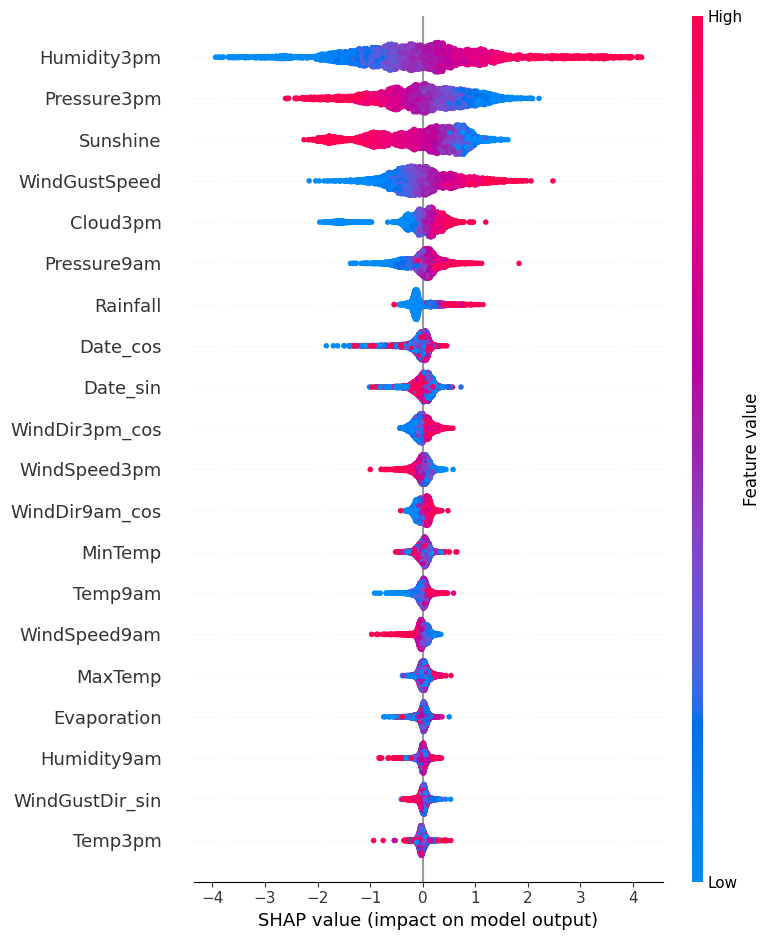

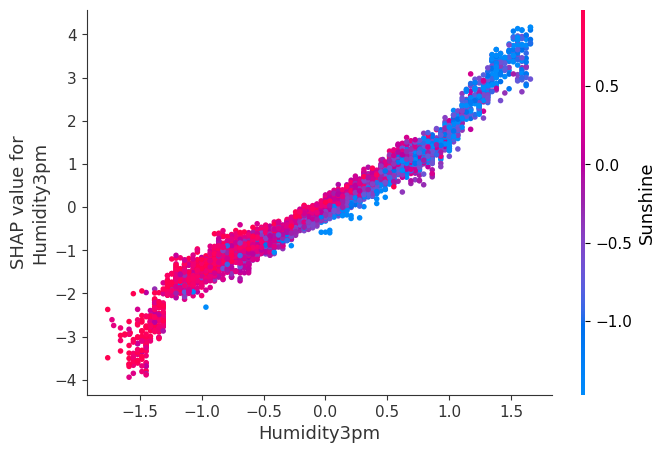

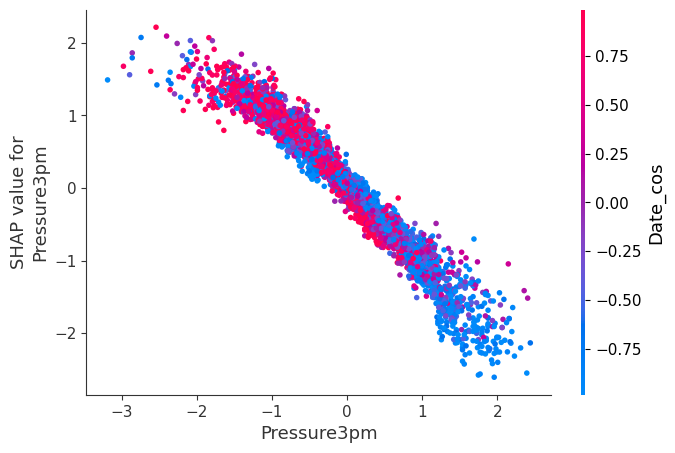

In [92]:
X_sample = X_train.sample(5000, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

# Summary plot : vue d'ensemble avec direction d'effet
shap.summary_plot(shap_values, X_sample)

# Dependence plot : effet d'une feature selon sa valeur
shap.dependence_plot("Humidity3pm", shap_values, X_sample)
shap.dependence_plot("Pressure3pm", shap_values, X_sample)